In [53]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# load the database read only and 
con = duckdb.connect("mimic_database.duckdb", read_only=True)

myTabs = con.sql("SHOW TABLES").df()
print(myTabs.iloc[:,0])


0             admissions
1              caregiver
2            chartevents
3                d_hcpcs
4        d_icd_diagnoses
5       d_icd_procedures
6                d_items
7             d_labitems
8         datetimeevents
9        demo_subject_id
10         diagnoses_icd
11              drgcodes
12                  emar
13           emar_detail
14           hcpcsevents
15              icustays
16      ingredientevents
17           inputevents
18             labevents
19    microbiologyevents
20                   omr
21          outputevents
22              patients
23              pharmacy
24                   poe
25            poe_detail
26         prescriptions
27       procedureevents
28        procedures_icd
29              provider
30              services
31             transfers
Name: name, dtype: str


In [ ]:
# look at the number of columns and approximate number of rows in each table, sorted by the number of rows
con.sql("SELECT table_name, column_count, estimated_size AS approx_rows "
        "FROM duckdb_tables() ORDER BY approx_rows DESC").show()

# choose a few tables to look at the structure of the data, and can add the commented section to seea few rows of data
for t in ["admissions", "icustays", "patients", "d_items", "chartevents"]:
    print("==", t)
    # con.sql(f"DESCRIBE {t}").show() # look at the type of data and column names
    con.sql(f"SUMMARIZE {t}").show() # look at the valuse for the data in this subset of tables
    # con.sql(f"SELECT * FROM {t} LIMIT 3").show() # can look at the native strucutre of the tables

┌──────────────────┬──────────────┬─────────────┐
│    table_name    │ column_count │ approx_rows │
│     varchar      │    int64     │    int64    │
├──────────────────┼──────────────┼─────────────┤
│ chartevents      │           11 │      668862 │
│ d_icd_diagnoses  │            3 │      109775 │
│ labevents        │           16 │      107727 │
│ d_hcpcs          │            4 │       89200 │
│ d_icd_procedures │            3 │       85257 │
│ emar_detail      │           33 │       72018 │
│ poe              │           12 │       45154 │
│ provider         │            1 │       40508 │
│ emar             │           12 │       35835 │
│ ingredientevents │           17 │       25728 │
│        ·         │            · │          ·  │
│        ·         │            · │          ·  │
│        ·         │            · │          ·  │
│ procedureevents  │           22 │        1468 │
│ transfers        │            7 │        1190 │
│ procedures_icd   │            6 │         722 │


100
All subject IDs in patients are present in admissions table
There were 48 in the admissions table with duplicate subject IDs
The number of admissions for each patient, sorted by number of admissions:


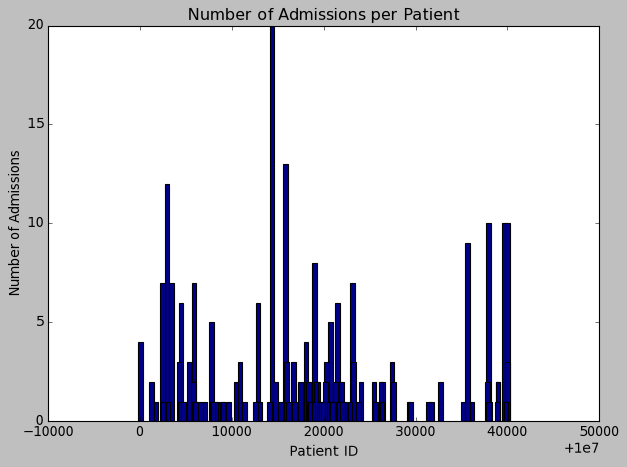

In [ ]:
# # start by looking at admissions, are there patients that are admitted frequently?  Are there any duplicate subject IDs?
# the patient information is stored in the patient table and the admissions
patientIDs = con.sql("SELECT subject_id FROM patients").df() # these are the unique patient IDs, there are 100 of them in this demo data
# now look in admissions
admissionIDs = con.sql("SELECT subject_id FROM admissions").df() # these are the patient IDs in the admissions table, there are 148 of them in this demo data
print(admissionIDs.subject_id.nunique()) # there are 100 unique patient IDs in the admissions table, so some patients have been admitted more than once

missingIDs = con.sql("SELECT subject_id FROM patients WHERE subject_id NOT IN (SELECT subject_id FROM admissions)").df() # these are the patient IDs in the admissions table, there are 148 of them in this demo data
# there are 100 unique patient IDs in the admissions table, so some patients have been admitted more than once
if missingIDs.empty:
    print("All subject IDs in patients are present in admissions table")

# # the subject_id is the unique patient ID, the hadm_id is the identifier for each hospital admission so repeated admissions would potentially show up there
duplicates = con.sql("SELECT subject_id FROM admissions GROUP BY subject_id HAVING COUNT(subject_id) > 1")
print(f"There were {len(duplicates)} in the admissions table with duplicate subject IDs")

## there were 48 repeated subject IDs in the admissions table, so I want to sort all the patients (100) by number of admissions
print("The number of admissions for each patient, sorted by number of admissions:")
numAdmByPatient = con.sql("SELECT subject_id, COUNT(subject_id) AS num_admissions FROM admissions GROUP BY subject_id ORDER BY num_admissions DESC").df()# .show() # could just show here
# print(numAdmByPatient) # print the dataframe instead of showing in the notebook
# make bar plot of the number of admissions for each patient

plt.bar(numAdmByPatient.subject_id, numAdmByPatient.num_admissions, color='darkblue', edgecolor='black', width = 500)
plt.title('Number of Admissions per Patient')
plt.xlabel('Patient ID')
plt.ylabel('Number of Admissions')

# Display the plot
plt.tight_layout()
plt.show()

In [ ]:
# 
